<a href="https://colab.research.google.com/github/balavardhansai/DSIP/blob/main/OPE_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving ytmp3free.cc_nee-jathaleka-video-song-maine-pyar-kiya-movie-salman-khan-bhagyashree-youtubemp3free.org.mp3 to ytmp3free.cc_nee-jathaleka-video-song-maine-pyar-kiya-movie-salman-khan-bhagyashree-youtubemp3free.org (1).mp3
Sample rate: 48000 Hz
Duration: 278.83 seconds
Finished cutoff: 500 Hz


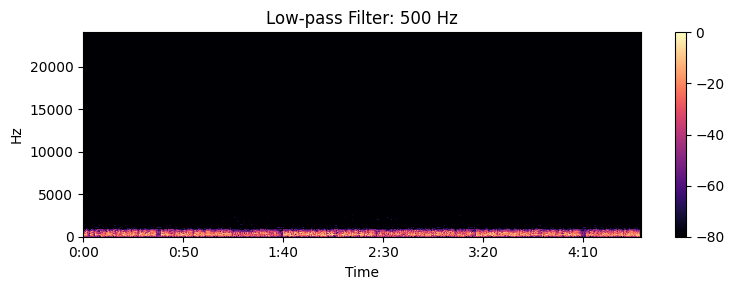

Finished cutoff: 1500 Hz


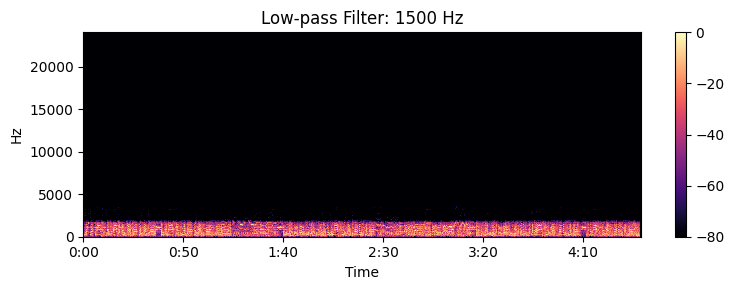

Finished cutoff: 3000 Hz


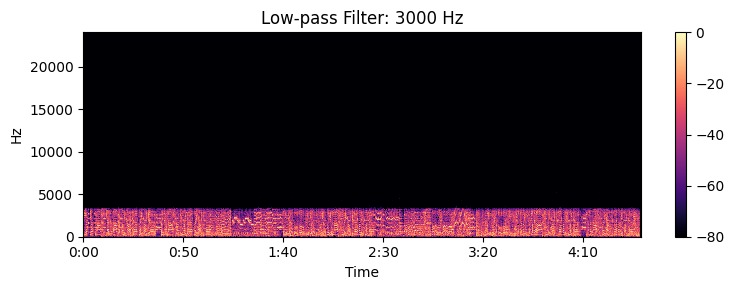

All filtering completed.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

!pip -q install librosa scipy pydub
!apt-get -qq install -y ffmpeg
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
from scipy.signal import firwin, fftconvolve
from pydub import AudioSegment
from google.colab import files
from IPython.display import Audio, display
uploaded = files.upload()
filename = next(iter(uploaded))
y, sr = librosa.load(filename, sr=None, mono=True)
print("Sample rate:", sr, "Hz")
print("Duration:", round(len(y) / sr, 2), "seconds")
def save_mp3(name, signal):
    peak = np.max(np.abs(signal))
    if peak > 0:
        signal = signal * (0.95 / peak)
    samples = np.clip(
        signal * 32767, -32768, 32767
    ).astype(np.int16)

    audio = AudioSegment(
        samples.tobytes(),
        frame_rate=sr,
        sample_width=2,
        channels=1
    )
    audio.export(name, format="mp3", bitrate="192k")
cutoffs = [500, 1500, 3000]
output_files = []
for cutoff in cutoffs:
    if cutoff >= sr / 2:
        print(f"Skipping {cutoff} Hz")
        continue
    taps = firwin(201, cutoff, fs=sr, window="hamming")
    filtered = fftconvolve(y, taps, mode="same")
    name = f"lowpass_{cutoff}Hz.mp3"
    save_mp3(name, filtered)
    output_files.append(name)
    print(f"Finished cutoff: {cutoff} Hz")
    D = librosa.amplitude_to_db(
        np.abs(librosa.stft(filtered, n_fft=1024, hop_length=512)),
        ref=np.max
    )
    plt.figure(figsize=(8, 3))
    librosa.display.specshow(
        D, sr=sr, hop_length=512,
        x_axis="time", y_axis="hz",
        vmin=-80, vmax=0
    )
    plt.title(f"Low-pass Filter: {cutoff} Hz")
    plt.colorbar()
    plt.tight_layout()
    plt.show()
print("All filtering completed.")
for name in output_files:
    files.download(name)


In [1]:

!pip -q install librosa scipy soundfile
import numpy as np
import librosa
import soundfile as sf
from scipy.signal import butter, sosfiltfilt
from google.colab import files
uploaded = files.upload()
filename = next(iter(uploaded))
y, sr = librosa.load(filename, sr=22050, mono=True)
print("Sample rate:", sr)
print("Duration:", round(len(y) / sr, 2), "seconds")
lowcut = 300
highcut = 3000
sos = butter(
    4, [lowcut, highcut],
    btype="bandpass", fs=sr, output="sos"
)
vocal_band = sosfiltfilt(sos, y)
background = y - vocal_band

sf.write("vocal_band.wav", vocal_band, sr)
sf.write("background_residual.wav", background, sr)

print("Processing complete!")
files.download("vocal_band.wav")
files.download("background_residual.wav")


Saving ytmp3free.cc_nee-jathaleka-video-song-maine-pyar-kiya-movie-salman-khan-bhagyashree-youtubemp3free.org.mp3 to ytmp3free.cc_nee-jathaleka-video-song-maine-pyar-kiya-movie-salman-khan-bhagyashree-youtubemp3free.org (3).mp3
Sample rate: 22050
Duration: 278.83 seconds
Processing complete!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>